In [70]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
%load_ext autoreload
%autoreload 2
from fwh_analysis import FWHDataset, FWHPlotter


def fft(dataset, col='P_obs', title="FFT Spectrum", max_freq=None, auto_scale=True):
    if type(dataset) == pd.DataFrame:
        time = dataset['Time'].values
        pressure = dataset[col].values
    elif type(dataset) == FWHDataset:
        time = dataset.data['Time'].values
        pressure = dataset.data[col].values
    
    dt = time[1] - time[0]
    N = len(time)
    
    freqs = np.fft.rfftfreq(N, d=dt)
    fft_complex = np.fft.rfft(pressure)
    
    amplitude = 2.0 / N * np.abs(fft_complex)
    amplitude[0] = amplitude[0] / 2
    phases = np.angle(fft_complex)
    
    if auto_scale and max_freq is None:
        max_amp = np.max(amplitude)
        threshold = max(0.01 * max_amp, 1e-3) 
        
        significant_indices = np.where(amplitude > threshold)[0]
        
        if len(significant_indices) > 0:
            highest_significant_freq = freqs[significant_indices[-1]]
            max_freq = min(highest_significant_freq * 1.15, freqs[-1])
        else:
            max_freq = freqs[-1]  # Fallback if flatline

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(freqs, amplitude, linestyle='-', color='b', markersize=4)
    
    ax.set_title(title, weight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude (Pa)')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    if max_freq:
        ax.set_xlim(left=0, right=max_freq)
        
    plt.tight_layout()
    plt.show()
    
    return freqs, amplitude, phases

def dft(t, p, f_1bpf, num_harmonics=10):
    if type(t) == pd.core.series.Series:
        T_period = t.iloc[-1] - t.iloc[0]
    elif type(t) == list:
        T_period = t[-1] - t[0]
    freqs = np.zeros(num_harmonics)
    amps = np.zeros(num_harmonics)
    phases = np.zeros(num_harmonics)

    for n in range(1, num_harmonics + 1):
        freqs[n-1] = n * f_1bpf
        omega_n = 2 * np.pi * freqs[n-1]

        real = np.trapezoid(p * np.cos(omega_n * t), t) * (2.0 / T_period)
        imag = np.trapezoid(p * np.sin(omega_n * t), t) * (2.0 / T_period)

        amps[n-1] = np.sqrt(real ** 2 + imag **2)
        phases[n-1] = np.arctan2(-imag, real)

    return freqs, amps, phases

# def dft_spatial(theta_rad, p_theta, num_modes):
#     theta_full = np.append(theta_rad, 2 * np.pi)
#     p_full = np.append(p_theta, p_theta[0])
    
#     modes = np.arange(1, num_modes + 1)
#     amps = np.zeros(num_modes)
#     phases = np.zeros(num_modes)

#     for i, m, in enumerate(modes):
#         real = np.trapezoid(p_full * np.cos(m * theta_full), theta_full) / np.pi
#         imag = np.trapezoid(p_full * np.sin(m * theta_full), theta_full) / np.pi

#         amps[i] = np.sqrt(real **2 + imag **2)
#         phases[i] = np.arctan2(-imag, real)

#     return modes, amps, phases


# def dft_spatial(p_theta):
#     N = len(p_theta)
    
#     # Compute single-sided FFT for real input
#     fft_result = np.fft.rfft(p_theta)
    
#     # Normalize amplitude

#     return modes, amps, phases

def dft_spatial(p_theta, side='double'):
    N = len(p_theta)
    
    # Compute full two-sided FFT
    if side == 'double':
        fft_result = np.fft.fft(p_theta)
        fft_result = np.fft.fftshift(fft_result)
        modes = np.fft.fftshift(np.fft.fftfreq(N)) * N
        amps = 2.0 * np.abs(fft_result) / N
        
        dc_idx = np.where(modes == 0)[0][0]
        amps[dc_idx] = amps[dc_idx] / 2.0 
        phases = np.angle(fft_result)

    elif side == 'single':
        fft_result = np.fft.rfft(p_theta)
        amps = 2.0 * np.abs(fft_result) / N
        amps[0] = amps[0] / 2.0  

        modes = np.arange(len(amps))

    phases = np.angle(fft_result)
    return modes, amps, phases

def dft_plot(freqs, amps, analysis='temporal', scale='linear', title=None):
    if scale == 'linear':
        pass
    elif scale == 'db':
        p_ref = 2e-5
        amps = 20 * np.log10((amps / np.sqrt(2)) / p_ref)

    fig, ax = plt.subplots(figsize=(8,5))
    markerline, stemlines, baseline = ax.stem(freqs, amps, basefmt=' ')
    plt.setp(markerline, marker='o', color='red', markersize=6)
    plt.setp(stemlines, color='black', ls='--', linewidth=1.2)

    for x, y in zip(freqs, amps):
        y_offset = max(amps) * 0.05
        if y < 0:
            y = 0
        ax.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=9)

    if analysis == 'temporal':
        ax.set_xlabel('Frequency (Hz)', fontweight='bold')
        ax.set_title(f"DFT Extraction ({len(freqs)}) Harmonics, Base Frequency = {freqs[0]} Hz")
    elif analysis == 'spatial':
        ax.set_xlabel('Spatial Harmonic Number')
        ax.set_title('DFT Extraction of Spatial Lobes' + title if title is not None else 'DFT Extraction of Spatial Lobes')

    ax.set_ylabel('Amplitdue (Pa)' if scale == 'linear' else 'Sound Pressure Level (dB), Reference = 2e-5 Pa')
    
    ax.set_ylim(0, max(amps) * 1.2)
    ax.set_xticks(freqs)
    # ax.set_xticks(i for i in range(len(freqs)))
    plt.xticks(rotation=45)
    ax.grid(True, ls=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

def extract_spatial_snapshot(datasets, target_time, col='P_obs'):
    """
    Extracts a purely spatial array (e.g., pressure) across all observers 
    at a specific time step, without altering the array size for plotting.
    """
    n_obs = len(datasets)
    angles_rad = np.linspace(0, 2 * np.pi, n_obs, endpoint=False)
    spatial_pressures = []

    for ds in datasets:
        # Handle both raw DataFrames and your FWHDataset objects
        df = ds.data if hasattr(ds, 'data') else ds
        
        # Find the row closest to the target time
        idx = (np.abs(df['Time'] - target_time)).argmin()
        spatial_pressures.append(df[col].iloc[idx])

    return angles_rad, np.array(spatial_pressures)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [321]:
# filepath = Path('data_260715/P_test')
# observers = ['01', '10', '19', '28']
# p_values = range(10, 90, 10)

# for obs in observers:
#     datasets = []
#     labels = []
#     for p in p_values:
#         path = filepath / f"P{p}_{obs}.dat"

#         if path.exists():
#             datasets.append(FWHDataset(filepath=path))
#             labels.append(f"P = {p}")
    
#     if len(datasets) > 1:
#         # 1. Separate the finest resolution to act as your truth/reference
#         ref_dataset = datasets[-1] 
        
#         # 2. Keep the rest as comparisons
#         comp_datasets = datasets[:-1]
#         comp_labels = labels[:-1]
        
#         title_str = f"Time Step Convergence Check: Observer {obs}"
        
#         # 3. Use the '*' operator to unpack the list into your *comparisons argument
#         FWHPlotter.plot_pressure(
#             ref_dataset, 
#             *comp_datasets, 
#             labels=comp_labels, 
#             title=title_str, 
#             error_method='l2',
#             ref_col='P_obs'
#         )

In [322]:
# filepath = Path('data_260715/24Sources_12Harmonics_thirddisk_numerical')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with 72 X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# dft_plot(freqs, amps, analysis='temporal', scale='db')
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,#snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')
# dft_plot(modes, amps, analysis='spatial', scale='db')

In [323]:
# n_sources = 36

# filepath = Path(f'data_260729/{n_sources}Sources_12Harmonics_analytical')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'P100_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with {n_sources} X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# dft_plot(freqs, amps, analysis='temporal', scale='db')
# obs_files = sorted(filepath.glob(f'P100_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=0,#snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')
# dft_plot(modes, amps, analysis='spatial', scale='db')

In [324]:
# n_sources = 12

# filepath = Path(f'data_260729/{n_sources}Sources_12Harmonics_analytical')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'P100_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with {n_sources} X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# dft_plot(freqs, amps, analysis='temporal', scale='db')
# obs_files = sorted(filepath.glob(f'P100_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=0,#snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')
# dft_plot(modes, amps, analysis='spatial', scale='db')

In [325]:
# n_sources = 8

# filepath = Path(f'data_260729/{n_sources}Sources_12Harmonics_analytical')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'P100_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with {n_sources} X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# dft_plot(freqs, amps, analysis='temporal', scale='db')
# obs_files = sorted(filepath.glob(f'P100_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=0,#snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')
# dft_plot(modes, amps, analysis='spatial', scale='db')

In [2]:
# n_sources = 18

# filepath = Path(f'data_260729/{n_sources}Sources_3Harmonics_analytical')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'P100_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with {n_sources} X 3 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 3)
# dft_plot(freqs, amps, analysis='temporal')
# dft_plot(freqs, amps, analysis='temporal', scale='db')
# obs_files = sorted(filepath.glob(f'P100_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=9)
# dft_plot(modes, amps, analysis='spatial')
# dft_plot(modes, amps, analysis='spatial', scale='db')

In [3]:
# n_sources = 36

# filepath = Path(f'data_260729/{n_sources}Sources_6Harmonics_analytical')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'P100_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with {n_sources} X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# dft_plot(freqs, amps, analysis='temporal', scale='db')
# obs_files = sorted(filepath.glob(f'P100_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=0,#snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')
# dft_plot(modes, amps, analysis='spatial', scale='db')

In [4]:
# filepath = Path('data_260714/108Sources_12Harmonics')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with 72 X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# dft_plot(freqs, amps, analysis='temporal', scale='db')
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,#snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')
# dft_plot(modes, amps, analysis='spatial', scale='db')

In [5]:
# filepath = Path('data_260714/72Sources_12Harmonics')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with 72 X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# dft_plot(freqs, amps, analysis='temporal', scale='db')
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')
# dft_plot(modes, amps, analysis='spatial', scale='db')

In [6]:
# filepath = Path('data_260826/1Sources_M0.5')
# obs_id = 10
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'1 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='1 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='1 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [7]:
# filepath = Path('data_260826/2Sources_M0.5')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'2 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='1 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='2 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [8]:
# filepath = Path('data_260826/3Sources_M0.5')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='3 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='3 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [9]:
# filepath = Path('data_260826/4Sources_M0.5')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'4 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='4 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='4 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [10]:
# filepath = Path('data_260826/8Sources_M0.5')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'8 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='8 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='8 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [11]:
# filepath = Path('data_260826/16Sources_M0.5')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'16 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='16 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='16 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [12]:
# filepath = Path('data_260826/32Sources_M0.5')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [13]:
# filepath = Path('data_260826/1Sources_M0.5_fratio4')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [14]:
# filepath = Path('data_260826/2Sources_M0.5_fratio4')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [15]:
# filepath = Path('data_260826/8Sources_M0.5_fratio4')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [16]:
# filepath = Path('data_260826/16Sources_M0.5_fratio4')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [17]:
# filepath = Path('data_260826/32Sources_M0.5_fratio4')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                          legend=False, x_axis='normalised')


# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [ ]:
filepath = Path('data_260826/32Sources_M0.5')
obs_id = 19
temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
                         legend=False, x_axis='normalised')


obs_files = sorted(filepath.glob(f'rotating*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]
FWHPlotter.plot_directivity_snapshot(reference=datasets,
                                     target_time=47.808e-3/2,
                                     col='P_obs',
                                     title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2',
                                     legend=False)

FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=20.8, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
                             title='32 Rotating Monopoles | M=0.5 | Frequency Ratio = 2')

angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

modes, amps, phases = dft_spatial(p_theta)
dft_plot(modes, amps, analysis='spatial', scale='linear')

In [18]:
# filepath = Path('data_260708/72Sources_12Harmonics')
# obs_id = 12
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with 72 X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False)
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_half = datasets[0].data['Time'].max() / 2
# snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
#                                  , num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,
#                                      col='P_obs',
#                                      is_polar=False)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')

In [19]:
# filepath = Path('data_260708/2lobes-0deg')
# obs_id = 21
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Two Monopoles with Equal Phases\nTime History at Observer {obs_id}',
#                          legend=False)
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 5)
# dft_plot(freqs, amps)
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_half = datasets[0].data['Time'].max() / 2
# snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
#                                  , num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,
#                                      col='P_obs',
#                                      is_polar=False)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
# dft_plot(modes, amps, analysis='spatial')
# # print(amps, phases)

# # theta = np.linspace(0, 2*np.pi, 36)
# # pressure = 0
# # for i in range(len(amps)):
# #     amp = amps[i]
# #     phase = phases[i]
# #     mode = modes[i]
# #     pressure += amp * np.cos(mode * theta + phase)

# # fig, ax = plt.subplots()
# # ax.plot(theta, pressure)

In [20]:
# filepath = Path('data_260708/2lobes-180deg')
# obs_id = 21
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Two Monopoles with Phase Angles $\phi$=90$^\circ$, 270$^\circ$\nTime History at Observer {obs_id}',
#                          legend=False)
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 10)
# dft_plot(freqs, amps)
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_half = datasets[0].data['Time'].max() / 2
# snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
#                                  , num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,
#                                      col='P_obs',
#                                      is_polar=False)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
# dft_plot(modes, amps, analysis='spatial')
# # print(amps, phases)

# # theta = np.linspace(0, 2*np.pi, 36)
# # pressure = 0
# # for i in range(len(amps)):
# #     amp = amps[i]
# #     phase = phases[i]
# #     mode = modes[i]
# #     pressure += amp * np.cos(mode * theta + phase)

# # fig, ax = plt.subplots()
# # ax.plot(theta, pressure)

In [21]:
# filepath = Path('data_260708/3lobes-0deg')
# obs_id = 21
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Three Monopoles Equal Phases\nTime History at Observer {obs_id}',
#                          legend=False)
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 10)
# dft_plot(freqs, amps)
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_half = datasets[0].data['Time'].max() / 2
# snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
#                                  , num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,
#                                      col='P_obs',
#                                      is_polar=False)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
# dft_plot(modes, amps, analysis='spatial')
# # print(amps, phases)


# # theta = np.linspace(0, 2*np.pi, 36)
# # pressure = 0
# # for i in range(len(amps)):
# #     amp = amps[i]
# #     phase = phases[i]
# #     mode = modes[i]
# #     pressure += amp * np.cos(mode * theta + phase)

# # fig, ax = plt.subplots()
# # ax.plot(theta, pressure)

In [22]:
# filepath = Path('data_260708/3lobes-120deg')
# obs_id = 21
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Three Monopoles with Phase Angles $\phi$=0$^\circ$, 120$^\circ$, 240$^\circ$\nTime History at Observer {obs_id}',
#                          legend=False)
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 10)
# dft_plot(freqs, amps)
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_half = datasets[0].data['Time'].max() / 2
# snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
#                                  , num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,
#                                      col='P_obs',
#                                      is_polar=False)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
# dft_plot(modes, amps, analysis='spatial')
# # print(amps, phases)

# # theta = np.linspace(0, 2*np.pi, 36)
# # pressure = 0
# # for i in range(len(amps)):
# #     amp = amps[i]
# #     phase = phases[i]
# #     mode = modes[i]
# #     pressure += amp * np.cos(mode * theta + phase)

# # fig, ax = plt.subplots()
# # ax.plot(theta, pressure)

In [23]:
# filepath = Path('data_260708/4lobes-0deg')
# obs_id = 21
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Four Monopoles Equal Phases\nTime History at Observer {obs_id}',
#                          legend=False)
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 10)
# dft_plot(freqs, amps)
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_half = datasets[0].data['Time'].max() / 2
# snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
#                                  , num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,
#                                      col='P_obs',
#                                      is_polar=False)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
# dft_plot(modes, amps, analysis='spatial')
# # print(amps, phases)

# # theta = np.linspace(0, 2*np.pi, 36)
# # pressure = 0
# # for i in range(len(amps)):
# #     amp = amps[i]
# #     phase = phases[i]
# #     mode = modes[i]
# #     pressure += amp * np.cos(mode * theta + phase)

# # fig, ax = plt.subplots()
# # ax.plot(theta, pressure)

In [24]:
# filepath = Path('data_260708/4lobes-90deg')
# obs_id = 21
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Four Monopoles with Phase Angles $\phi$=0$^\circ$, 90$^\circ$, 180$^\circ$ 270$^\circ$\nTime History at Observer {obs_id}',
#                          legend=False)
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 10)
# dft_plot(freqs, amps)
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,
#                                      col='P_obs',
#                                      is_polar=False)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
# dft_plot(modes, amps, analysis='spatial')
# # print(amps, phases)

# # theta = np.linspace(0, 2*np.pi, 36)
# # pressure = 0
# # for i in range(len(amps)):
# #     amp = amps[i]
# #     phase = phases[i]
# #     mode = modes[i]
# #     pressure += amp * np.cos(mode * theta + phase)

# # fig, ax = plt.subplots()
# # ax.plot(theta, pressure)

In [68]:
# filepath = Path('data_260707/4lobes-Test')
# temporal_data = FWHDataset(filepath=filepath / 'ana_spatial_21.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title='Validation Data using Analytical Model of Decomposed Data')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 4)
# dft_plot(freqs, amps)
# obs_files = sorted(filepath.glob(f'ana_*.dat'))# datasets = [FWHDataset(filepath=f) for f in obs_files]

# FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=7e-3,
#                                      col='P_obs',
#                                      is_polar=False)

In [ ]:
# filepath = Path('data_260714/72Sources_12Harmonics_translating')
# obs_id = 19
# temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with 72 X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}',
#                          legend=False, x_axis='normalised')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
# dft_plot(freqs, amps, analysis='temporal')
# obs_files = sorted(filepath.glob(f'ana_*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]

# t_period = datasets[0].data['Time'].max()
# snapshot_times = np.linspace(0, t_period, num=5)

# angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=0,#snapshot_times,
#                                      col='P_obs',
#                                      is_polar=False,
#                                      legend=True)

# time = list(spatial_data.keys())[0]
# p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=36)
# dft_plot(modes, amps, analysis='spatial')

In [25]:
# mono_scan_path = Path('data_260715_REFERENCE') / 'WG_Mono.csv'
# mono_scan_df = pd.read_csv(mono_scan_path, names=['Time', 'P_obs']).sort_values(by='Time')
# FWHPlotter.plot_pressure(mono_scan_df, ref_col='P_obs')

# freqs, amps, phases = dft(mono_scan_df['Time'], mono_scan_df['P_obs'], 107.25, 16)
# dft_plot(freqs, amps, scale='db')

In [26]:
# ref_data_auto = pd.read_csv('data_260706_REFERENCE/woan_gregorek_pt_auto_xtime.csv', names=['Time','P_obs'])
# FWHPlotter.plot_pressure(ref_data_auto, ref_col='P_obs')
# # freq_amp = fft(ref_data_auto)
# freqs, amps, phases = dft(ref_data_auto['Time'], ref_data_auto['P_obs'], 107.25, 32)
# # fft_data = pd.DataFrame({'Frequency':[0], 'Amplitude':freq_amp[1], 'Phase':freq_amp[2],
#             #   'Phase (deg)':np.rad2deg(freq_amp[2])})
# dft_plot(freqs, amps, scale='db')

In [ ]:
spl = [101.0, 102.0, 103.0, 102.0, 100.5, 99.0, 97.5, 96.5,
       95.0, 93.5, 91.5, 90.0, 88.5, 87.5, 85.5, 84.0,
       82.5, 81.0, 79.5, 78.0, 76.5, 75.0, 74.0, 72.5,
       71.0, 70.0, 69.0, 68.0, 67.0, 66.0, 65.0, 58.5]

p_ref = 2e-5
p_rms = []
for i in spl:
    p_rms.append(p_ref * 10 ** (i/20))

from scipy.interpolate import interp1d
from scipy.fft import fft

raw_data = np.loadtxt('woan_gregorek_NEW.csv', skiprows=1, delimiter=',')

data = pd.DataFrame(raw_data, columns=['t', 'p'])

data = data.sort_values(by='t').drop_duplicates(subset='t')
t_T = data['t'].values
p = data['p'].values

# 2. Resample on a uniform grid (N=1024 for FFT efficiency and high resolution)
N = 1024
t_uniform = np.linspace(0, 9.324e-3, N, endpoint=False) 

f_interp = interp1d(t_T, p, kind='cubic', bounds_error=False, fill_value="extrapolate")
p_uniform = f_interp(t_uniform)

# 3. Perform FFT
p_fft = fft(p_uniform)

# 4. Extract phase for harmonics 1-32 (Index 0 is the DC offset)
phases_rad = np.angle(p_fft)
harmonic_phases = phases_rad[1:33]

In [27]:
# filepath = Path('data_260828/72Sources_12Harmonics')
# obs_id = 55
# temporal_data = FWHDataset(filepath=filepath / f'analytical_{obs_id}.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'72 Sources, 12 Harmonics | Stationary Monopole Ring',
#                          legend=False, x_axis='normalised')

# obs_files = sorted(filepath.glob(f'analytical*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=47.808e-3/2,
#                                      col='P_obs',
#                                      title='72 Sources, 12 Harmonics | Stationary Monopole Ring',
#                                      legend=False)

# FWHPlotter.plot_fft_spectrum(temporal_data, temporal_data, f_base=107.25, num_harmonics=12, ref_col='P_obs', window='rectangular', y_axis='pressure',
#                              title='72 Sources, 12 Harmonics | Stationary Monopole Ring')

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')

# # time = list(spatial_data.keys())[0]
# # p_theta = spatial_data[time]

# modes, amps, phases = dft_spatial(p_theta)
# dft_plot(modes, amps, analysis='spatial', scale='linear')

In [181]:
# n, M, nu = 8, 0.5, 8

# if M == 0.5: 
#     color = 'blue' 
# else: 
#     color = 'red'

# filepath = Path(f'data_260830/{n}Sources_M{M}_fratio{nu}/')
# obs_id = '022'
# temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')

# pressure, time = temporal_data.data['P_obs'], temporal_data.data['Time']
# time_period = time.max()

# dt = time.iloc[1] - time.iloc[0]
# N = len(pressure)
# freqs = np.fft.rfftfreq(N, d=dt)
# fft_amp = (2.0 / N) * np.abs(np.fft.rfft(pressure))

# p_ref = 2e-5
# spl_ana = 20 * np.log10((fft_amp / np.sqrt(2)) / p_ref + 1e-12)

# T_ref = time_period
# f_bpf = 1.0 / T_ref
# harmonics = np.arange(1, 33)
# ana_peaks = []

# for h in harmonics:
#     target_f = h * f_bpf
#     idx = np.argmin(np.abs(freqs - target_f))
#     ana_peaks.append(spl_ana[idx])

# fig, ax1 = plt.subplots(figsize=(8,6))
# ax1.plot(time / time_period, pressure, c=color, label=rf"M={M}, $\nu$={nu}")
# ax1.grid(True)
# ax1.legend()
# ax1.set_ylabel('Acoustic Pressure (Pa)')
# ax1.set_xlabel(f't/T, T={time_period * 1000:.3f} ms')
# ax1.set_xlim(left=0.0, right=1.0)
# ax1.set_title(f'Time History Signal for {n} Rotating Sources at M={M} and Frequency Ratio {nu}')

# plt.show()

# obs_files = sorted(filepath.glob(f'rotating*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=0, #np.linspace(0, time.max(), 4),#47.808e-3/2,
#                                      col='P_obs',
#                                      title='Spatial Pressure Lobes at In-Plane Observers',
#                                      legend=True, scale=1)

# angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=2e-3, col='P_obs')
# modes, amps, phases = dft_spatial(p_theta)

# amp_spl = 20 * np.log10(((amps) / np.sqrt(2)) / p_ref)

# fig, (ax1, ax2) = plt.subplots(figsize=(12,6), ncols=2, sharey=True)

# ax1.vlines(harmonics, ymin=0, ymax=ana_peaks, color='black', ls=':')
# ax1.plot(harmonics, ana_peaks, marker='s', color='none', markeredgecolor=color)#, label=rf"M={M}, $\nu$={nu}")
# ax1.set_xlabel("Temporal Harmonic (n)")
# ax1.set_ylabel(r"Sound Pressure Level (dB), Reference = 2 $\times$ 10$^{-5}$ Pa")
# ax1.grid(True)
# ax1.set_ylim(bottom=0, top=max(ana_peaks) * 1.2)

# for x, y in zip(harmonics, ana_peaks):
#     y_offset = max(ana_peaks) * 0.05
#     if y < 0:
#         y = 0
#     ax1.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=8, rotation=90)


# ax2.vlines(modes, ymin=0, ymax=amp_spl, color='black', ls=':')
# ax2.plot(modes, amp_spl, marker='o', color='none', markeredgecolor=color)

# for x, y in zip(modes, amp_spl):
#     y_offset = max(amp_spl) * 0.05
#     if y < 0:
#         y = 0
        
#     if x <= 32:
#         ax2.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=8, rotation=90)

# ax2.set_xlabel('Spatial Harmonic (m)')

# valid_xticks = [m for m in modes if m <= 32]
# ax2.set_xticks(valid_xticks)

# # ax2.set_title("Spectra of Spatial Lobes", fontsize=15)
# ax2.grid(True, alpha=0.6, which='major', ls=':')
# ax2.set_ylim(bottom=0, top=max(amp_spl) * 1.2)
# ax2.set_xlim(left=-1, right=33) # Added a tiny margin so markers don't clip on the borders

# fig.suptitle(f"Temporal and Spatial Spectra of {n} Sources Rotating at Mach Number={M} and Frequency Ratio {nu}")
# plt.xticks(rotation=60)
# plt.tight_layout()
# plt.show()

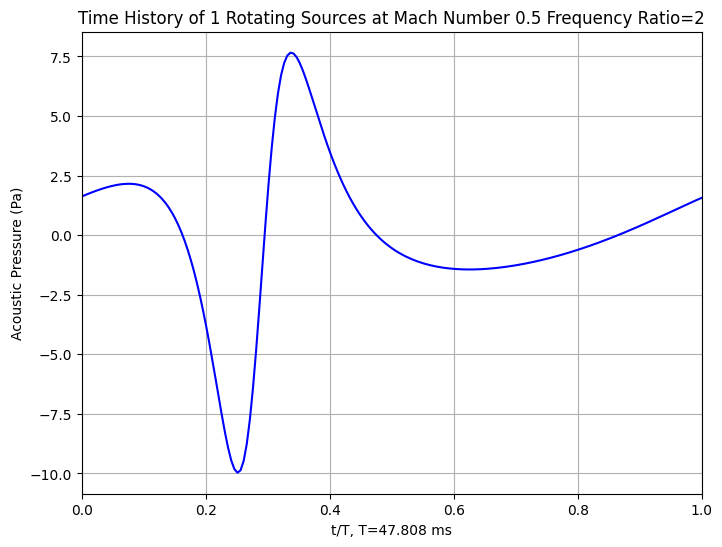

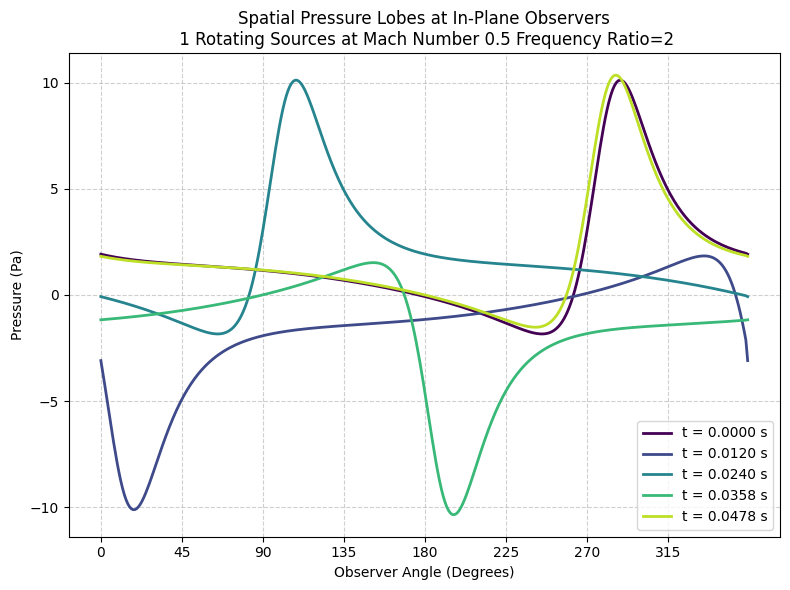

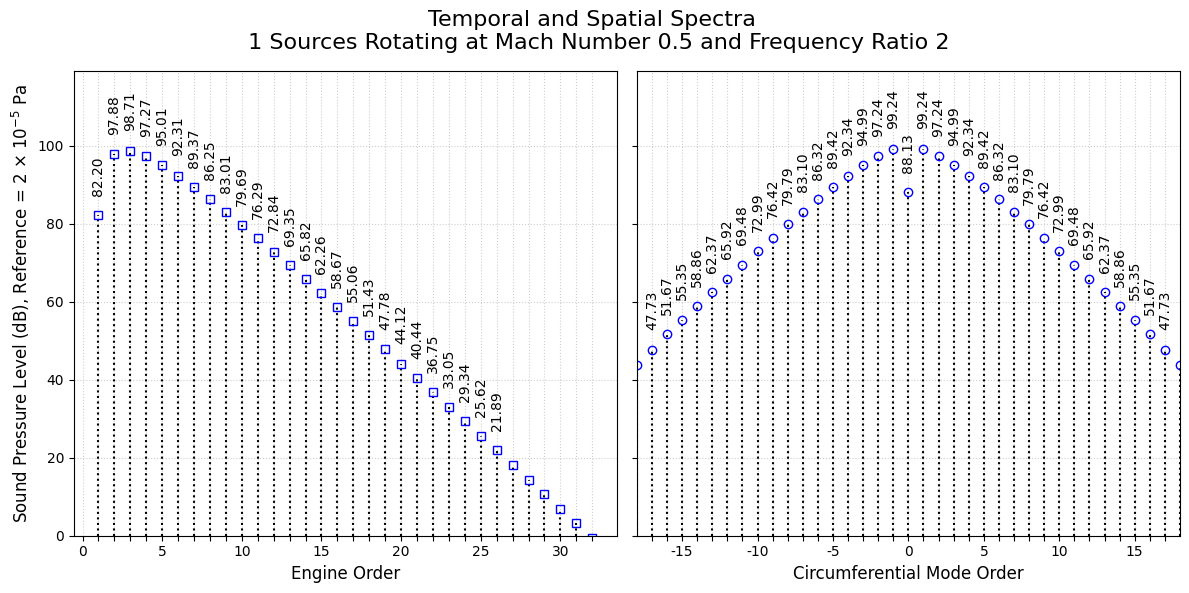

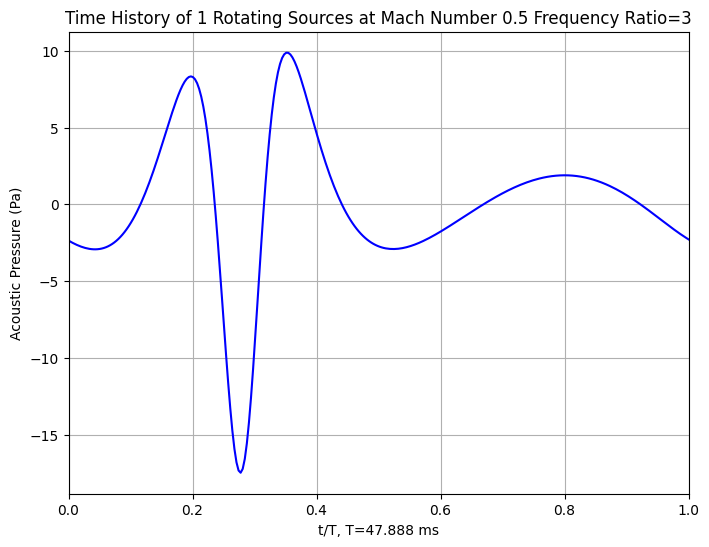

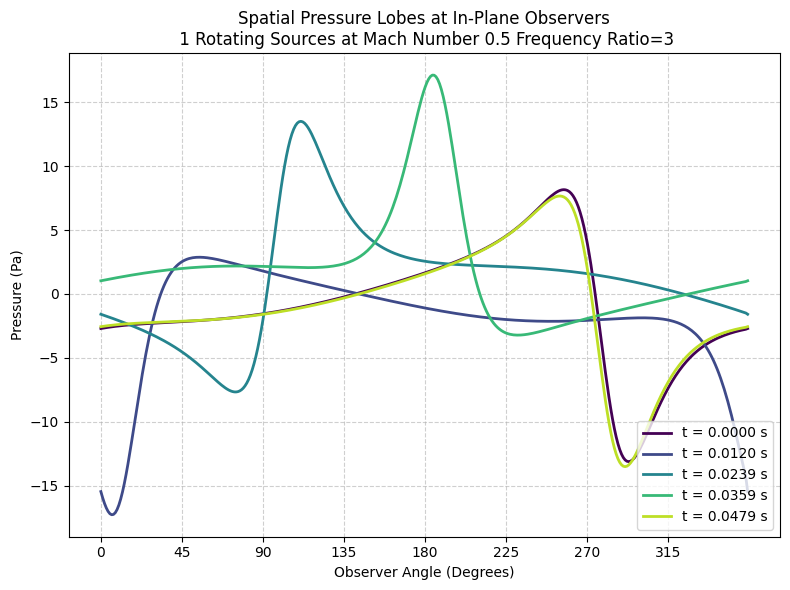

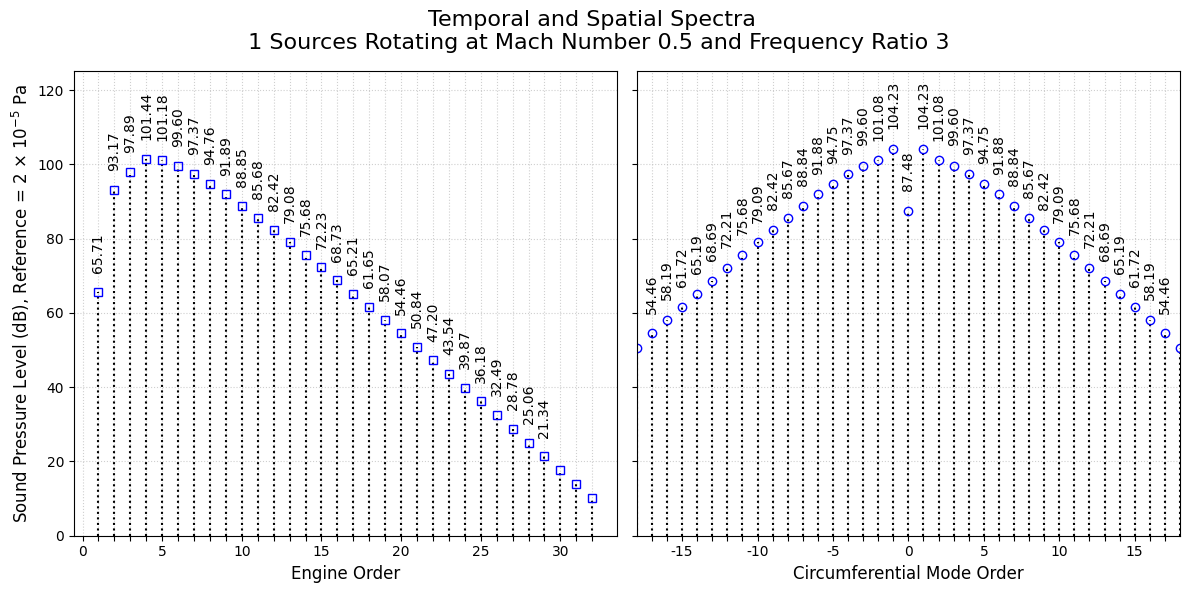

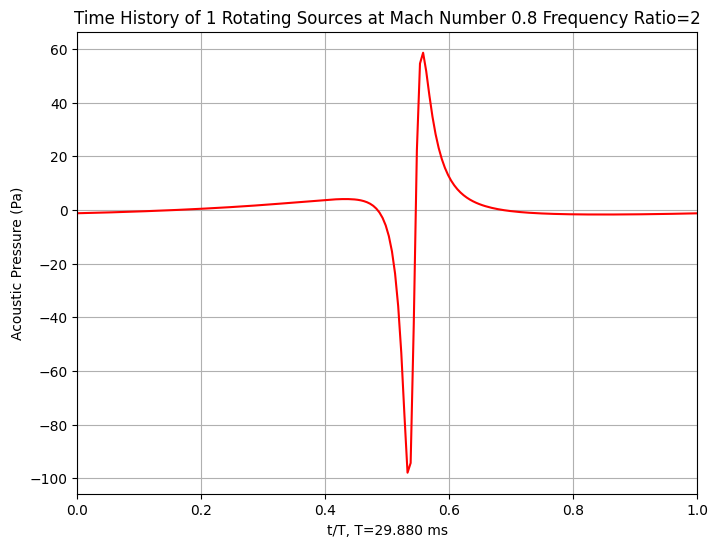

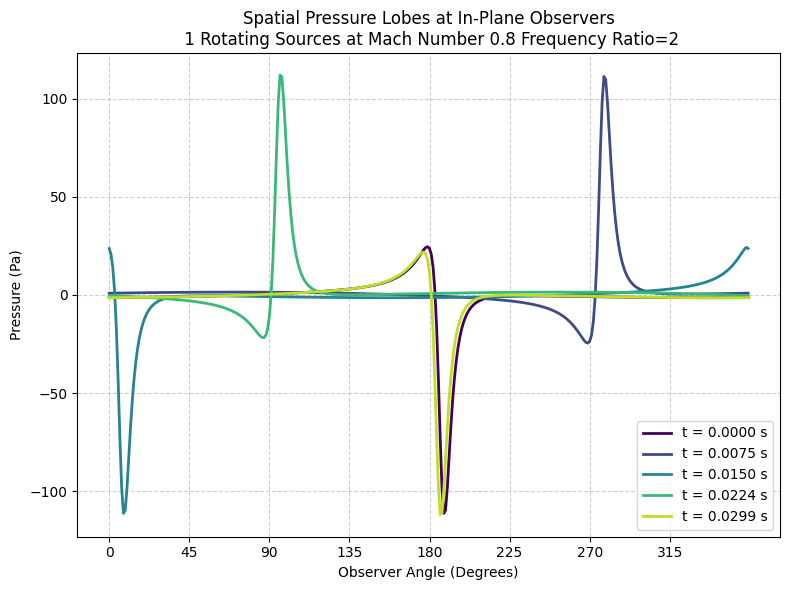

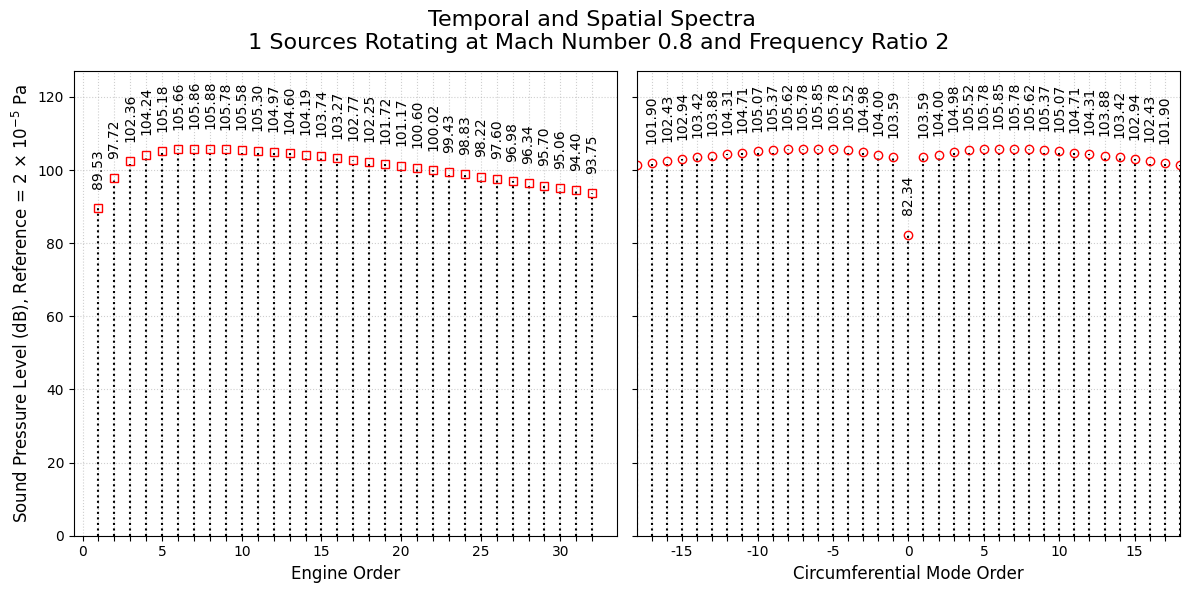

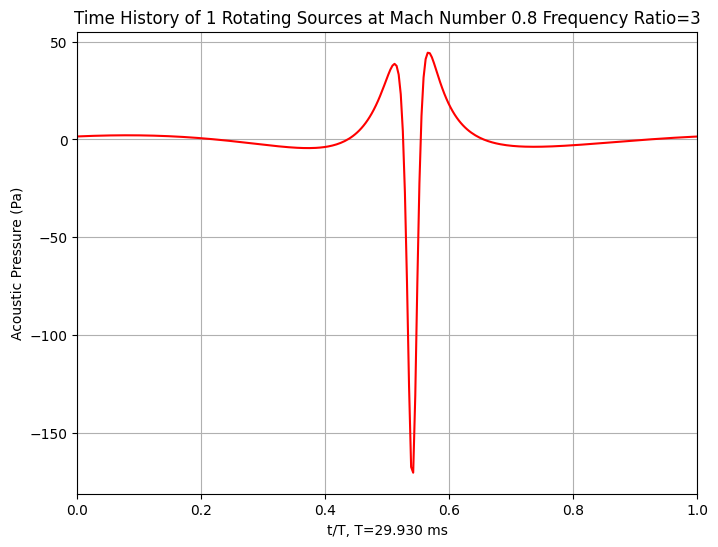

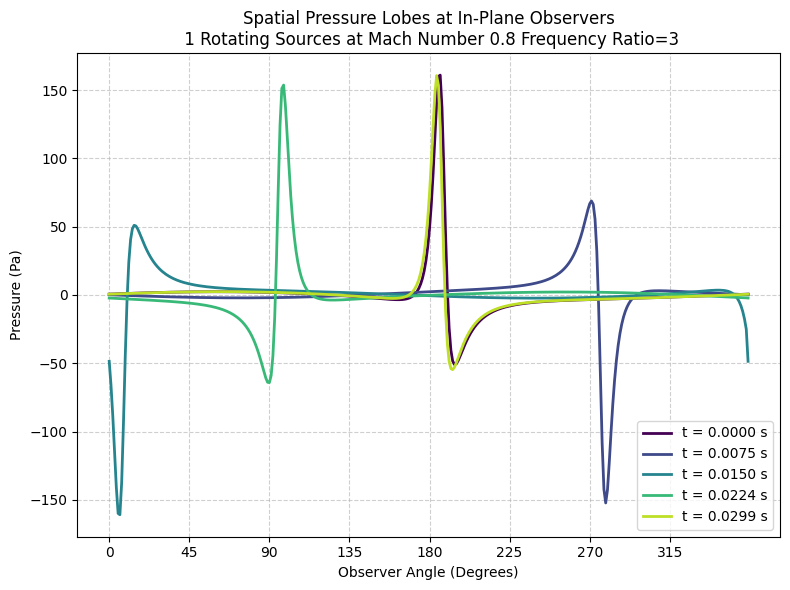

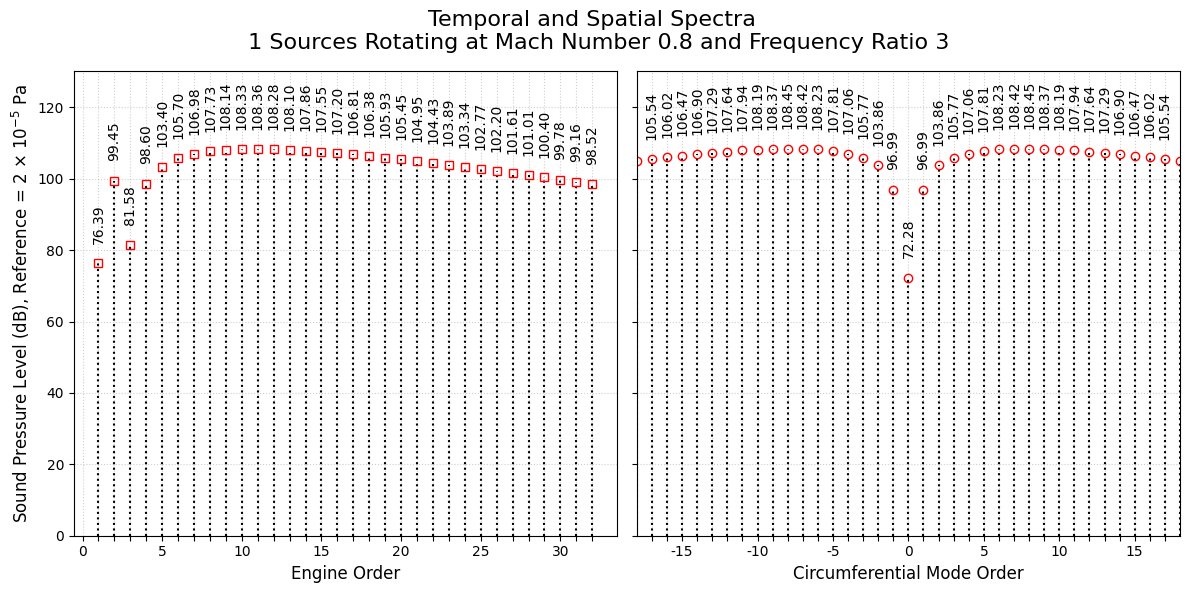

In [82]:
N_sources, Mach_number, freq_ratio = [1], [0.5, 0.8], [2,3]
max_har = 32  # Defined explicitly to parameterize the formatting

for n in N_sources:
    for M in Mach_number:
        for nu in freq_ratio:
            if M == 0.5: 
                color = 'blue' 
            else: 
                color = 'red'

            filepath = Path(f'data_260831/{n}Sources_M{M}_fratio{nu}_phaselagged/')
            obs_id = '022'
            temporal_data = FWHDataset(filepath=filepath / f'rotating_{obs_id}.dat')

            pressure, time = temporal_data.data['P_obs'], temporal_data.data['Time']
            time_period = time.max()

            dt = time.iloc[1] - time.iloc[0]
            N = len(pressure)
            freqs = np.fft.rfftfreq(N, d=dt)
            fft_amp = (2.0 / N) * np.abs(np.fft.rfft(pressure))

            p_ref = 2e-5
            spl_ana = 20 * np.log10((fft_amp / np.sqrt(2)) / p_ref + 1e-12)

            T_ref = time_period
            f_bpf = 1.0 / T_ref
            harmonics = np.arange(1, max_har + 1)
            ana_peaks = []

            for h in harmonics:
                target_f = h * f_bpf
                idx = np.argmin(np.abs(freqs - target_f))
                ana_peaks.append(spl_ana[idx])

            fig, ax1 = plt.subplots(figsize=(8,6))
            ax1.plot(time / time_period, pressure, c=color, label=rf"M={M}, $\nu$={nu}")
            ax1.grid(True)
            # ax1.legend()
            ax1.set_ylabel('Acoustic Pressure (Pa)')
            ax1.set_xlabel(f't/T, T={time_period * 1000:.3f} ms')
            ax1.set_xlim(left=0.0, right=1.0)
            ax1.set_title(f"Time History of {n} Rotating Sources at Mach Number {M} Frequency Ratio={nu}")

            plt.show()
            # fig.savefig(f'0_thesis_figures/rotating/N{n}_M0{int(M*10)}_rat{nu}_timehistor.png')

            obs_files = sorted(filepath.glob(f'rotating*.dat'))
            datasets = [FWHDataset(filepath=f) for f in obs_files]

            FWHPlotter.plot_directivity_snapshot(reference=datasets,
                                                target_time=np.linspace(0, time.max(), 5),
                                                col='P_obs',
                                                title=f'Spatial Pressure Lobes at In-Plane Observers\n {n} Rotating Sources at Mach Number {M} Frequency Ratio={nu}',
                                                legend=True, scale=1)

            angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=2e-3, col='P_obs')
            modes, amps, phases = dft_spatial(p_theta)

            amp_spl = 20 * np.log10(((amps) / np.sqrt(2)) / (p_ref + 1e-15))

            harmonic_ticks = np.arange(0, max_har + 1, 1)
            harmonic_labels = [str(x) if x % 5 == 0 else '' for x in harmonic_ticks]

            fig, (ax1, ax2) = plt.subplots(figsize=(12,6), ncols=2, sharey=True)

            # --- AX1: Temporal (Engine Order) ---
            ax1.vlines(harmonics, ymin=0, ymax=ana_peaks, color='black', ls=':')
            ax1.plot(harmonics, ana_peaks, marker='s', color='none', markeredgecolor=color)
            ax1.set_xlabel("Engine Order", fontsize=12)
            ax1.set_ylabel(r"Sound Pressure Level (dB), Reference = 2 $\times$ 10$^{-5}$ Pa", fontsize=12)
            ax1.grid(True, alpha=0.6, which='major', ls=':')
            ax1.set_ylim(bottom=0, top=max(ana_peaks) * 1.2)
            ax1.set_xticks(harmonic_ticks)
            ax1.set_xticklabels(harmonic_labels)

            for x, y in zip(harmonics, ana_peaks):
                y_offset = max(ana_peaks) * 0.05
                if y < 0:
                    y = 0
                # Threshold filter to drop the noise floor
                if y > 20:
                    ax1.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=10, rotation=90)

            # --- AX2: Spatial (Circumferential Mode Order) ---
            ax2.vlines(modes, ymin=0, ymax=amp_spl, color='black', ls=':')
            ax2.plot(modes, amp_spl, marker='o', color='none', markeredgecolor=color)
            ax2.set_xlabel('Circumferential Mode Order', fontsize=12)

            # Integer limit for symmetric bounds
            max_har_sym = int(max_har / 2 + 1)

            for x, y in zip(modes, amp_spl):
                y_offset = max(amp_spl) * 0.05
                if y < 0:
                    y = 0
                # Match the text filtering to the new visible axis limits
                if -max_har_sym <= x <= max_har_sym and y > 20:
                    ax2.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=10, rotation=90)

            # Symmetric axis formatting for the full FFT using the integer limit
            symmetric_ticks = np.arange(-max_har_sym, max_har_sym + 1, 1)
            symmetric_labels = [str(x) if x % 5 == 0 else '' for x in symmetric_ticks]

            ax2.set_xticks(symmetric_ticks)
            ax2.set_xticklabels(symmetric_labels)
            ax2.grid(True, alpha=0.6, which='major', ls=':')
            ax2.set_ylim(bottom=0, top=max(amp_spl) * 1.2)
            # Replaced the float division with the calculated integer limit to prevent border clipping issues
            ax2.set_xlim(left=-max_har_sym - 1, right=max_har_sym + 1)

            fig.suptitle(f"Temporal and Spatial Spectra \n {n} Sources Rotating at Mach Number {M} and Frequency Ratio {nu}", fontsize=16)
            plt.tight_layout()
            # plt.show()
            fig.savefig(f'0_thesis_figures/rotating/N{n}_M0{int(M*10)}_rat{nu}_DFT.png')

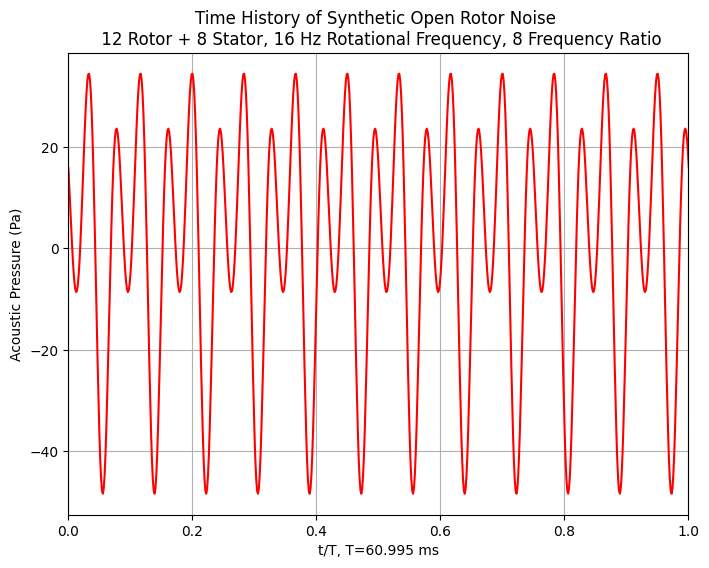

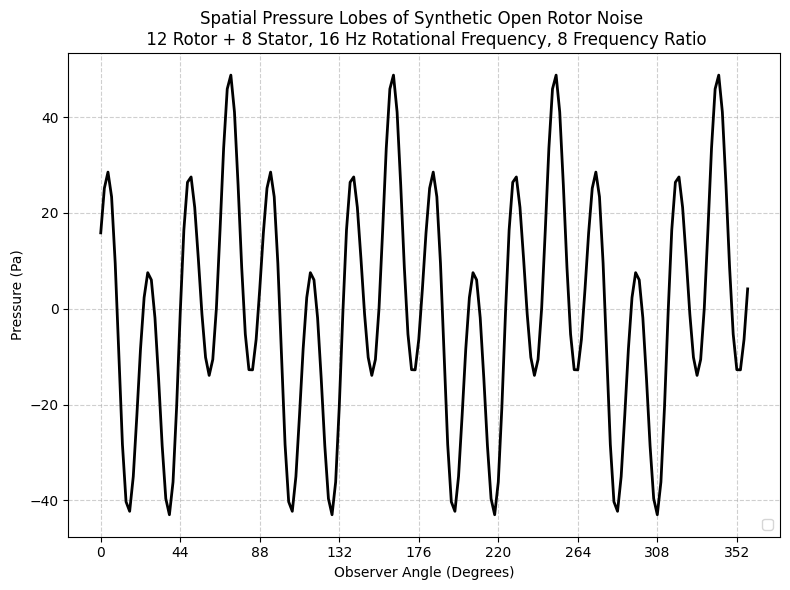

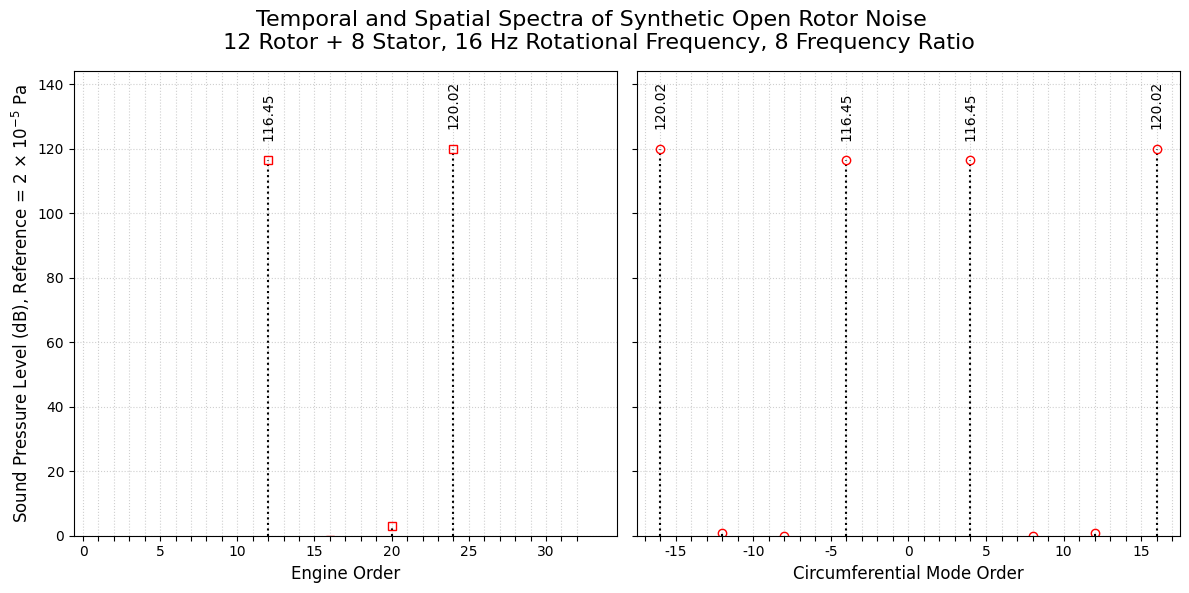

In [83]:

filepath = Path(f'data_260902/OpenFan_Fratio_Omega/plane_z')
obs_id = '001'
temporal_data = FWHDataset(filepath=filepath / f'analytical_{obs_id}.dat')

max_har = 33
pressure, time = temporal_data.data['P_obs'], temporal_data.data['Time']
time_period = time.max() / 2

dt = time.iloc[1] - time.iloc[0]
N = len(pressure)
freqs = np.fft.rfftfreq(N, d=dt)
fft_amp = (2.0 / N) * np.abs(np.fft.rfft(pressure))

p_ref = 2e-5
spl_ana = 20 * np.log10((fft_amp / np.sqrt(2)) / p_ref + 1e-12)

T_ref = time_period
f_bpf = 1.0 / T_ref
harmonics = np.arange(1,max_har+1)
ana_peaks = []

for h in harmonics:
    target_f = h * f_bpf
    idx = np.argmin(np.abs(freqs - target_f))
    ana_peaks.append(spl_ana[idx])

fig, ax1 = plt.subplots(figsize=(8,6))
ax1.plot(time / time_period, pressure, c=color, label=rf"M={M}, $\nu$={nu}")
ax1.grid(True)
# ax1.legend()
ax1.set_ylabel('Acoustic Pressure (Pa)')
ax1.set_xlabel(f't/T, T={time_period * 1000:.3f} ms')
ax1.set_xlim(left=0.0, right=1.0)
ax1.set_title(f"Time History of Synthetic Open Rotor Noise \n 12 Rotor + 8 Stator, 16 Hz Rotational Frequency, 8 Frequency Ratio")

plt.show()
# fig.savefig(f'0_thesis_figures/rotating/N{n}_M0{int(M*10)}_rat{nu}_timehistory')

obs_files = sorted(filepath.glob(f'analytical*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]




FWHPlotter.plot_directivity_snapshot(reference=datasets,
                                    #  target_time=np.linspace(0, time.max(), 5),#[0.0, 0.012, 0.024, 0.036],#,#47.808e-3/2,
                                    target_time=0,
                                     col='P_obs',
                                     title=f"Spatial Pressure Lobes of Synthetic Open Rotor Noise \n 12 Rotor + 8 Stator, 16 Hz Rotational Frequency, 8 Frequency Ratio",
                                     legend=True, scale=1)




angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')
modes, amps, phases = dft_spatial(p_theta)

amp_spl = 20 * np.log10(((amps) / np.sqrt(2)) / (p_ref + 1e-15))

harmonic_ticks = np.arange(0, max_har, 1)
harmonic_labels = [str(x) if x % 5 == 0 else '' for x in harmonic_ticks]

fig, (ax1, ax2) = plt.subplots(figsize=(12,6), ncols=2, sharey=True)

# --- AX1: Temporal (Engine Order) ---
ax1.vlines(harmonics, ymin=0, ymax=ana_peaks, color='black', ls=':')
ax1.plot(harmonics, ana_peaks, marker='s', color='none', markeredgecolor=color)
ax1.set_xlabel("Engine Order", fontsize=12)
ax1.set_ylabel(r"Sound Pressure Level (dB), Reference = 2 $\times$ 10$^{-5}$ Pa", fontsize=12)
ax1.grid(True, alpha=0.6, which='major', ls=':')
ax1.set_ylim(bottom=0, top=max(ana_peaks) * 1.2)
ax1.set_xticks(harmonic_ticks)
ax1.set_xticklabels(harmonic_labels)

for x, y in zip(harmonics, ana_peaks):
    y_offset = max(ana_peaks) * 0.05
    if y < 0:
        y = 0
    # Threshold filter to drop the noise floor
    if y > 20:
        ax1.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=10, rotation=90)

# --- AX2: Spatial (Circumferential Mode Order) ---
ax2.vlines(modes, ymin=0, ymax=amp_spl, color='black', ls=':')
ax2.plot(modes, amp_spl, marker='o', color='none', markeredgecolor=color)
ax2.set_xlabel('Circumferential Mode Order', fontsize=12)

max_har_sym = int(max_har / 2 + 1)

for x, y in zip(modes, amp_spl):
    y_offset = max(amp_spl) * 0.05
    if y < 0:
        y = 0
    # Match the text filtering to your new visible axis limits
    if -max_har_sym <= x <= max_har_sym and y > 20:
        ax2.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=10, rotation=90)

# Symmetric axis formatting for the full FFT using the integer limit
symmetric_ticks = np.arange(-max_har_sym, max_har_sym + 1, 1)
symmetric_labels = [str(x) if x % 5 == 0 else '' for x in symmetric_ticks]

ax2.set_xticks(symmetric_ticks)
ax2.set_xticklabels(symmetric_labels)
ax2.grid(True, alpha=0.6, which='major', ls=':')
ax2.set_ylim(bottom=0, top=max(amp_spl) * 1.2)
ax2.set_xlim(left=-max_har /2 -1, right=max_har /2 +1)

fig.suptitle(f"Temporal and Spatial Spectra of Synthetic Open Rotor Noise \n 12 Rotor + 8 Stator, 16 Hz Rotational Frequency, 8 Frequency Ratio", fontsize=16)
plt.tight_layout()
plt.show()

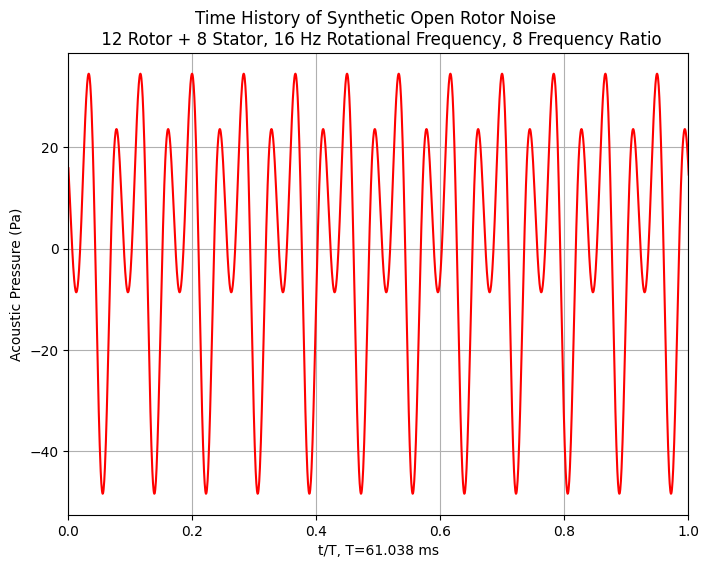

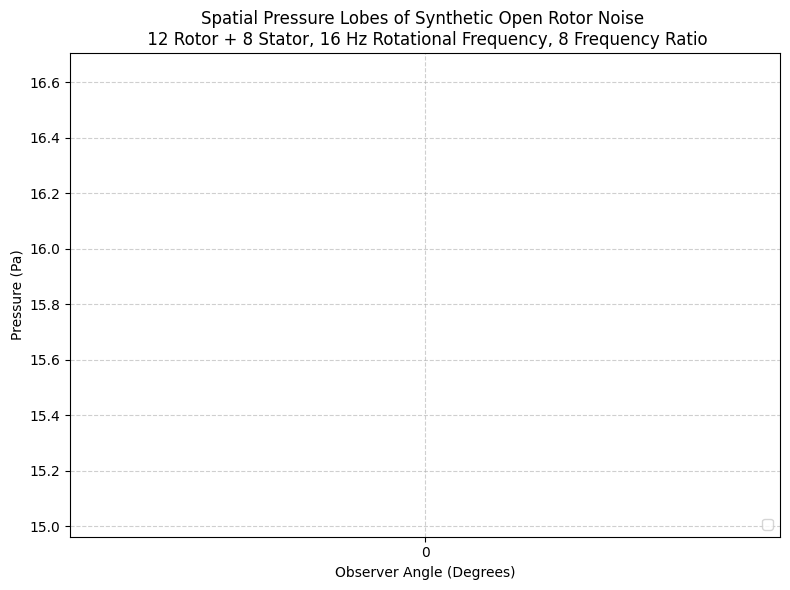

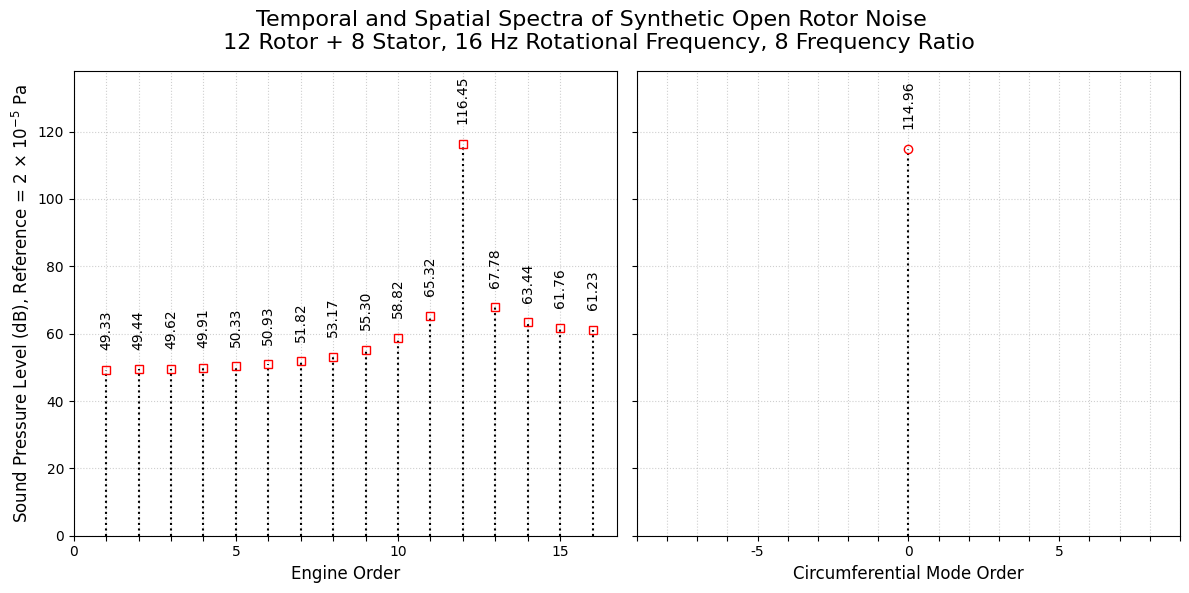

In [ ]:

filepath = Path(f'data_260902/OpenFan_XPSweep/plane_z')
obs_id = '001'
temporal_data = FWHDataset(filepath=filepath / f'analytical_{obs_id}.dat')

max_har = 16
pressure, time = temporal_data.data['P_obs'], temporal_data.data['Time']
# Hard-lock the frequency to the exact physical input
rotor_speed_rpm = 983
f_rot = rotor_speed_rpm / 60
time_period = 1.0 / f_rot

dt = time.iloc[1] - time.iloc[0]
N = len(pressure)
freqs = np.fft.rfftfreq(N, d=dt)
fft_amp = (2.0 / N) * np.abs(np.fft.rfft(pressure))

p_ref = 2e-5
spl_ana = 20 * np.log10((fft_amp / np.sqrt(2)) / p_ref + 1e-15)

# Use the exact physical frequency for the comb filter
harmonics = np.arange(1, max_har + 1)
ana_peaks = []

for h in harmonics:
    target_f = h * f_rot
    idx = np.argmin(np.abs(freqs - target_f))
    ana_peaks.append(spl_ana[idx])

fig, ax1 = plt.subplots(figsize=(8,6))
ax1.plot(time / time_period, pressure, c=color, label=rf"M={M}, $\nu$={nu}")
ax1.grid(True)
# ax1.legend()
ax1.set_ylabel('Acoustic Pressure (Pa)')
ax1.set_xlabel(f't/T, T={time_period * 1000:.3f} ms')
ax1.set_xlim(left=0.0, right=1.0)
ax1.set_title(f"Time History of Synthetic Open Rotor Noise \n 12 Rotor + 8 Stator, 16 Hz Rotational Frequency, 8 Frequency Ratio")

plt.show()
# fig.savefig(f'0_thesis_figures/rotating/N{n}_M0{int(M*10)}_rat{nu}_timehistory')

obs_files = sorted(filepath.glob(f'analytical*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]




FWHPlotter.plot_directivity_snapshot(reference=datasets,
                                    #  target_time=np.linspace(0, time.max(), 5),#[0.0, 0.012, 0.024, 0.036],#,#47.808e-3/2,
                                    target_time=0,
                                     col='P_obs',
                                     title=f"Spatial Pressure Lobes of Synthetic Open Rotor Noise \n 12 Rotor + 8 Stator, 16 Hz Rotational Frequency, 8 Frequency Ratio",
                                     legend=True, scale=1)




angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=0, col='P_obs')
modes, amps, phases = dft_spatial(p_theta)

amp_spl = 20 * np.log10(((amps) / np.sqrt(2)) / (p_ref + 1e-15))

harmonic_ticks = np.arange(0, max_har, 1)
harmonic_labels = [str(x) if x % 5 == 0 else '' for x in harmonic_ticks]

fig, (ax1, ax2) = plt.subplots(figsize=(12,6), ncols=2, sharey=True)

# --- AX1: Temporal (Engine Order) ---
ax1.vlines(harmonics, ymin=0, ymax=ana_peaks, color='black', ls=':')
ax1.plot(harmonics, ana_peaks, marker='s', color='none', markeredgecolor=color)
ax1.set_xlabel("Engine Order", fontsize=12)
ax1.set_ylabel(r"Sound Pressure Level (dB), Reference = 2 $\times$ 10$^{-5}$ Pa", fontsize=12)
ax1.grid(True, alpha=0.6, which='major', ls=':')
ax1.set_ylim(bottom=0, top=max(ana_peaks) * 1.2)
ax1.set_xticks(harmonic_ticks)
ax1.set_xticklabels(harmonic_labels)

for x, y in zip(harmonics, ana_peaks):
    y_offset = max(ana_peaks) * 0.05
    if y < 0:
        y = 0
    # Threshold filter to drop the noise floor
    if y > 20:
        ax1.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=10, rotation=90)

# --- AX2: Spatial (Circumferential Mode Order) ---
ax2.vlines(modes, ymin=0, ymax=amp_spl, color='black', ls=':')
ax2.plot(modes, amp_spl, marker='o', color='none', markeredgecolor=color)
ax2.set_xlabel('Circumferential Mode Order', fontsize=12)

max_har_sym = int(max_har / 2 + 1)

for x, y in zip(modes, amp_spl):
    y_offset = max(amp_spl) * 0.05
    if y < 0:
        y = 0
    # Match the text filtering to your new visible axis limits
    if -max_har_sym <= x <= max_har_sym and y > 20:
        ax2.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=10, rotation=90)

# Symmetric axis formatting for the full FFT using the integer limit
symmetric_ticks = np.arange(-max_har_sym, max_har_sym + 1, 1)
symmetric_labels = [str(x) if x % 5 == 0 else '' for x in symmetric_ticks]

ax2.set_xticks(symmetric_ticks)
ax2.set_xticklabels(symmetric_labels)
ax2.grid(True, alpha=0.6, which='major', ls=':')
ax2.set_ylim(bottom=0, top=max(amp_spl) * 1.2)
ax2.set_xlim(left=-max_har /2 -1, right=max_har /2 +1)

fig.suptitle(f"Temporal and Spatial Spectra of Synthetic Open Rotor Noise \n 12 Rotor + 8 Stator, 16 Hz Rotational Frequency, 8 Frequency Ratio", fontsize=16)
plt.tight_layout()
plt.show()

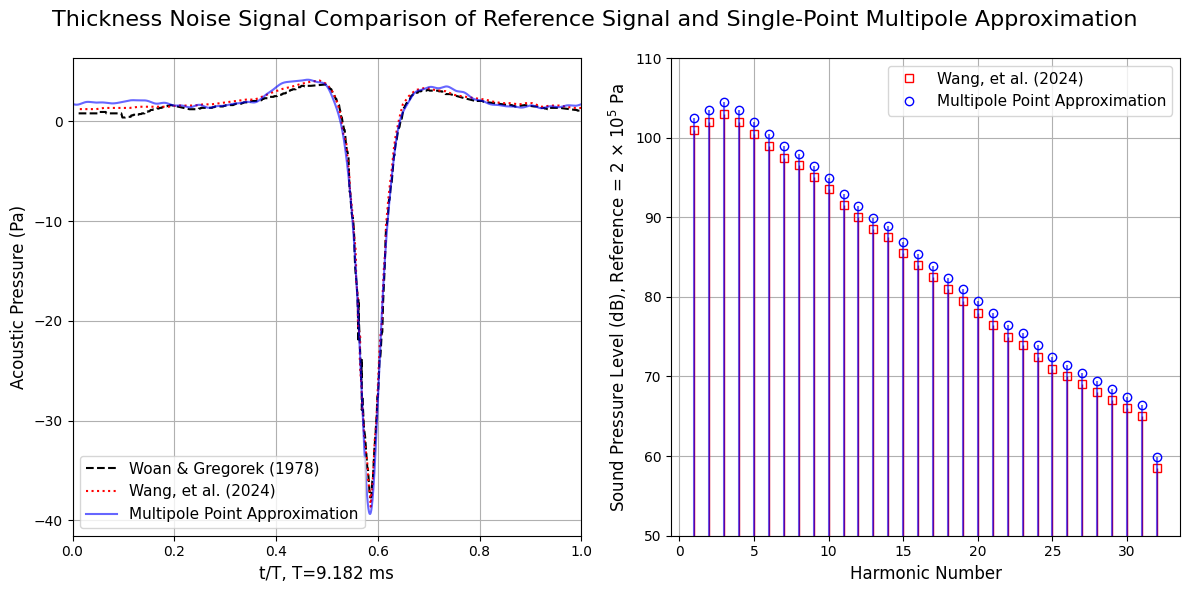

In [76]:
wang = pd.read_csv('data_260828/Wang_etal2024.csv', skiprows=1, names=['Time','Pressure'])
WG = pd.read_csv('data_260828/WG_Mono.csv',names=['Time','Pressure'])
time, pressure = wang.iloc[:,0], wang.iloc[:,1]
time_period = time.max()

spl = [101.0, 102.0, 103.0, 102.0, 100.5, 99.0, 97.5, 96.5,
       95.0, 93.5, 91.5, 90.0, 88.5, 87.5, 85.5, 84.0,
       82.5, 81.0, 79.5, 78.0, 76.5, 75.0, 74.0, 72.5,
       71.0, 70.0, 69.0, 68.0, 67.0, 66.0, 65.0, 58.5] # SPL data from Wang's paper

harmonic_number = [i for i in range(1, len(spl)+1)] # harmonics from Wang's paper


filepath = Path('data_260828/1Sources_32Harmonics_Point')
obs_id = '01'
temporal_data = FWHDataset(filepath=filepath / f'analytical_{obs_id}.dat')

p_ana = temporal_data.data['P_obs'] * 2
t_ana = temporal_data.data['Time']

dt = t_ana.iloc[1] - t_ana.iloc[0]
N = len(p_ana)
freqs = np.fft.rfftfreq(N, d=dt)
fft_amp = (2.0 / N) * np.abs(np.fft.rfft(p_ana))

p_ref = 2e-5
spl_ana = 20 * np.log10((fft_amp / np.sqrt(2)) / p_ref + 1e-12)

T_ref = t_ana.max()
f_bpf = 1.0 / T_ref
harmonics = np.arange(1, 33)
ana_peaks = []

for h in harmonics:
    target_f = h * f_bpf
    idx = np.argmin(np.abs(freqs - target_f))
    ana_peaks.append(spl_ana[idx])

fig, (ax1, ax2) = plt.subplots(figsize=(12,6), ncols=2)

ax1.plot(WG['Time'] / time_period, WG['Pressure'], label='Woan & Gregorek (1978)', ls='--', c='black')
ax1.plot(time / time_period, pressure, label='Wang, et al. (2024)', ls=':', c='red')

ax1.plot(temporal_data.data['Time'] / time_period, temporal_data.data['P_obs'] * 2, label='Multipole Point Approximation', c='blue', alpha=0.6)
ax1.grid(True)
ax1.set_ylabel("Acoustic Pressure (Pa)", fontsize=12)
ax1.set_xlabel(f't/T, T={time_period * 1000:.3f} ms', fontsize=12)
ax1.legend(loc='lower left',fontsize=11)
ax1.set_xlim(left=0.0, right=1.0)
# ax1.set_title("Comparison of Reference Propeller Signature and Multipole Approximation")

ax2.vlines(harmonic_number, ymax=spl, ymin=0, color='red', lw=1)
ax2.plot(harmonic_number, spl, marker='s', color='none', markeredgecolor='red', label='Wang, et al. (2024)')

ax2.vlines(harmonics, ymin=0, ymax=ana_peaks, color='blue', alpha=0.6)
ax2.plot(harmonics, ana_peaks, marker='o', color='none', markeredgecolor='blue', label='Multipole Point Approximation')
ax2.set_xlabel("Harmonic Number", fontsize=12)
ax2.set_ylabel(r"Sound Pressure Level (dB), Reference = 2 $\times$ 10$^5$ Pa", fontsize=12)
ax2.grid(True)
ax2.set_ylim(bottom=50, top=110)
ax2.legend(fontsize=11)

fig.suptitle("Thickness Noise Signal Comparison of Reference Signal and Single-Point Multipole Approximation", fontsize=16)
fig.tight_layout()
fig.subplots_adjust(top=0.90)
ax1.tick_params(labelsize=10)
ax2.tick_params(labelsize=10)
plt.show()

fig.savefig('0_thesis_figures/multipole/ref_vs_single_point_multipole.png')

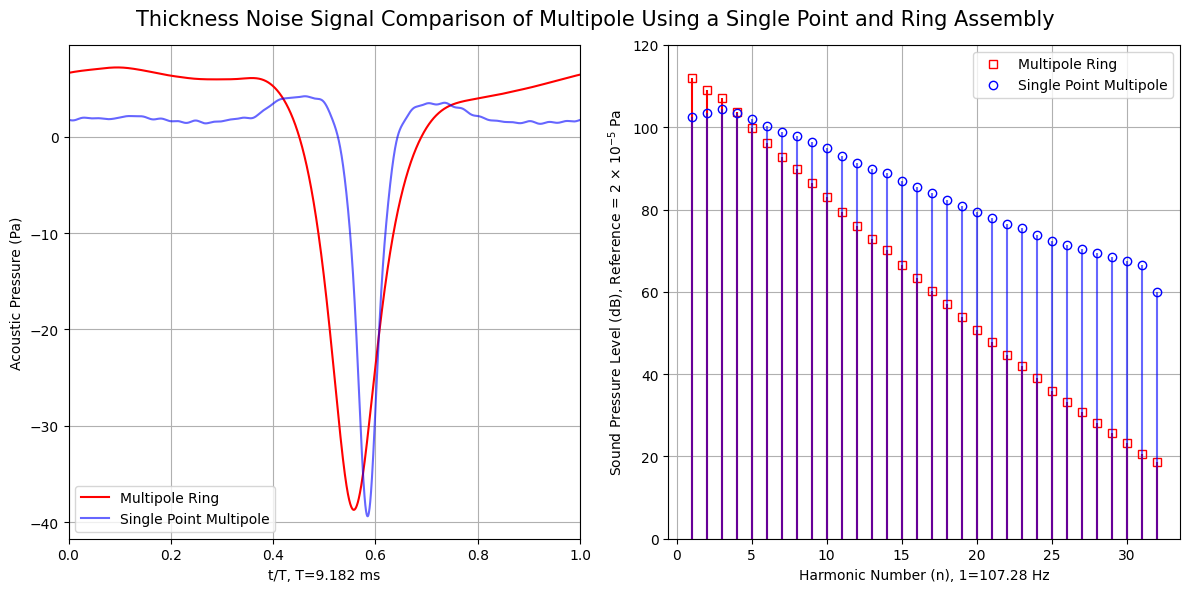

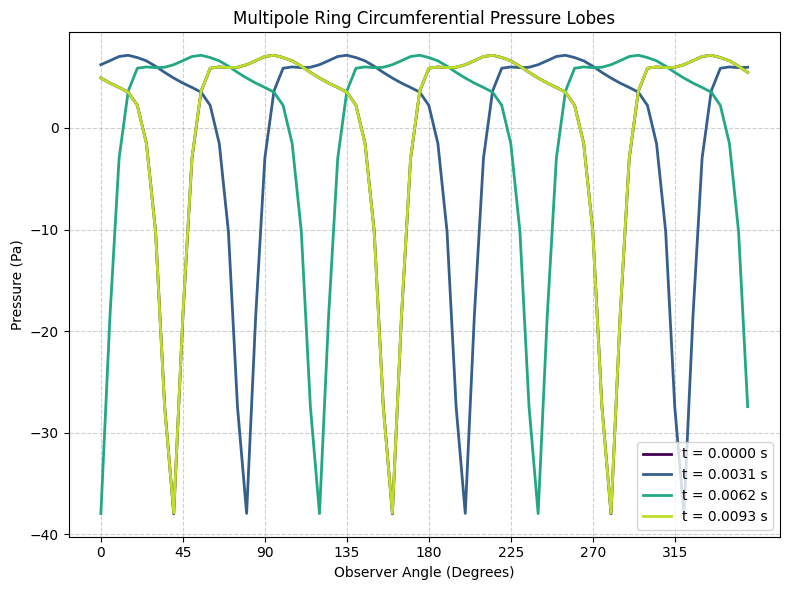

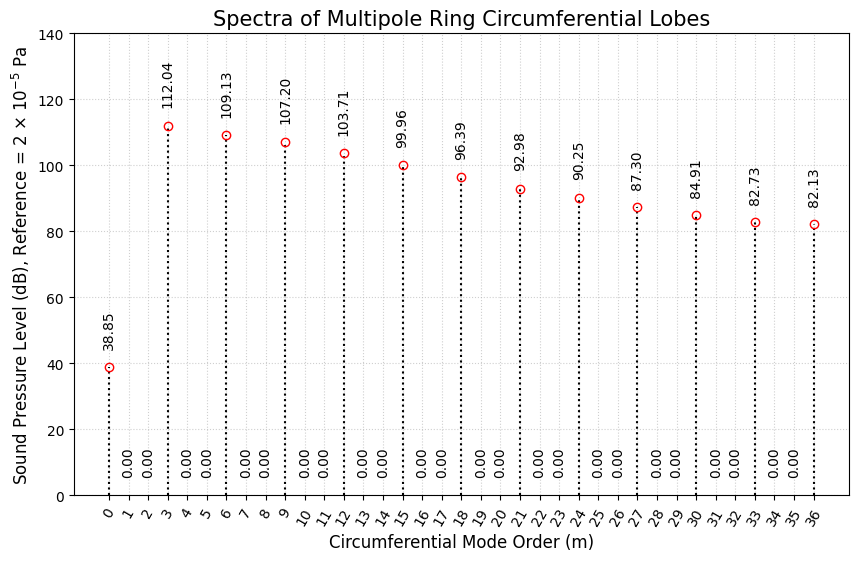

In [75]:
filepath = Path('data_260828/192Sources_32Harmonics_SinglePeriod_Z_Observers')
obs_id = 22
temporal_data = FWHDataset(filepath=filepath / f'analytical_{obs_id}.dat')

p_ring = temporal_data.data['P_obs'] /3 
t_ring = temporal_data.data['Time']

dt = t_ring.iloc[1] - t_ring.iloc[0]
N = len(p_ring)
freqs = np.fft.rfftfreq(N, d=dt)
fft_amp = (2.0 / N) * np.abs(np.fft.rfft(p_ring))

p_ref = 2e-5
spl_ana = 20 * np.log10((fft_amp / np.sqrt(2)) / p_ref + 1e-12)

T_ref = t_ring.max()
f_bpf = 1.0 / T_ref
harmonics_ring = np.arange(1, 33)
ana_peaks_ring = []

for h in harmonics_ring:
    target_f = h * f_bpf
    idx = np.argmin(np.abs(freqs - target_f))
    ana_peaks_ring.append(spl_ana[idx])

fig, (ax1, ax2) = plt.subplots(figsize=(12,6), ncols=2)
ax1.plot(t_ring / time_period, p_ring, c='red', label="Multipole Ring")
ax1.plot(t_ana / time_period, p_ana, label='Single Point Multipole', c='blue', alpha=0.6)
ax1.grid(True)
ax1.legend()
ax1.set_ylabel('Acoustic Pressure (Pa)')
ax1.set_xlabel(f't/T, T={time_period * 1000:.3f} ms')
ax1.set_xlim(left=0.0, right=1.0)

ax2.vlines(harmonics_ring, ymin=0, ymax=ana_peaks_ring, color='red')
ax2.plot(harmonics_ring, ana_peaks_ring, marker='s', color='none', markeredgecolor='red', label='Multipole Ring')
ax2.vlines(harmonics, ymin=0, ymax=ana_peaks, color='blue', alpha=0.6)
ax2.plot(harmonics, ana_peaks, marker='o', color='none', markeredgecolor='blue', label='Single Point Multipole')
ax2.set_xlabel(f"Harmonic Number (n), 1={f_bpf:.2f} Hz")
ax2.set_ylabel(r"Sound Pressure Level (dB), Reference = 2 $\times$ 10$^{-5}$ Pa")
ax2.grid(True)
ax2.set_ylim(bottom=0, top=120)
ax2.legend()
fig.suptitle("Thickness Noise Signal Comparison of Multipole Using a Single Point and Ring Assembly", fontsize=15)
fig.tight_layout()
fig.subplots_adjust(top=0.92)
# plt.show()
fig.savefig('0_thesis_figures/multipole/single_vs_ring_multipole.png')

obs_files = sorted(filepath.glob(f'analytical*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]
FWHPlotter.plot_directivity_snapshot(reference=datasets,
                                     target_time=np.linspace(0, t_ring.max(), 4),#47.808e-3/2,
                                     col='P_obs',
                                     title='Multipole Ring Circumferential Pressure Lobes',
                                     legend=True,
                                     scale=(1/3))

angles_rad, p_theta = extract_spatial_snapshot(datasets, target_time=2e-3, col='P_obs')
modes, amps, phases = dft_spatial(p_theta, 'single')
# dft_plot(modes, amps, analysis='spatial', scale='db')

amp_spl = 20 * np.log10(((amps / 3) / np.sqrt(2)) / p_ref)

fig, ax = plt.subplots(figsize=(10,6))
ax.vlines(modes, ymin=0, ymax=amp_spl, color='black', ls=':')
ax.plot(modes, amp_spl, marker='o', color='none', markeredgecolor='red')
for x, y in zip(modes, amp_spl):
    y_offset = max(amp_spl) * 0.05
    if y < 0:
        y = 0
    ax.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=10, rotation=90)
ax.set_xlabel('Circumferential Mode Order (m)', fontsize=12)
ax.set_ylabel(r"Sound Pressure Level (dB), Reference = 2 $\times$ 10$^{-5}$ Pa", fontsize=12)
ax.set_xticks(modes)
ax.set_title("Spectra of Multipole Ring Circumferential Lobes", fontsize=15)
ax.grid(True, alpha=0.6, which='major', ls=':')
ax.set_ylim(bottom=0, top=140)
# fig.subplots_adjust(top=0.88)
plt.xticks(rotation=60)
plt.show()
fig.savefig('0_thesis_figures/multipole/multipole_ring_spatialDFT.png')

In [47]:
import os

def extract_harmonic_amplitude(time, pressure, target_freq):
    """Extracts the peak pressure amplitude of a specific frequency using FFT."""
    N = len(time)
    dt = time[1] - time[0]
    
    yf = np.fft.fft(pressure)
    xf = np.fft.fftfreq(N, dt)
    idx = np.argmin(np.abs(xf - target_freq))
    
    return (2.0 / N) * np.abs(yf[idx])

def plot_elevation_directivity(data_dir, n_observers, f_fundamental, harmonics, 
                               scale='dB', p_ref=2e-5, 
                               legend=True, add_title=None):
    """
    Plots the out-of-plane directivity for specified harmonics.
    
    Parameters:
    - data_dir: Directory containing the 'analytical_XX.dat' files.
    - n_observers: Total number of observers in the circular array.
    - f_fundamental: The fundamental frequency of the rotor (Hz).
    - harmonics: List of integers representing the temporal harmonics to plot (e.g., [1, 2, 3]).
    - scale: 'linear' for Pascals, 'dB' for Sound Pressure Level.
    """
    # Assuming observers are evenly distributed in a full 360-degree circle
    angles = np.linspace(0, 2 * np.pi, n_observers, endpoint=False)
    
    # Dictionary to store the extracted directivity array for each harmonic
    directivity_data = {n: np.zeros(n_observers) for n in harmonics}
    
    for i in range(n_observers):
        filename = os.path.join(data_dir, f"analytical_{i+1:02d}.dat")
        
        if not os.path.exists(filename):
            print(f"Warning: {filename} missing. Skipping.")
            continue
            
        data = np.loadtxt(filename)
        time = data[:, 0]
        pressure = data[:, 1]
        
        for n in harmonics:
            amp = extract_harmonic_amplitude(time, pressure, n * f_fundamental)
            
            if scale == 'dB':
                # Convert peak amplitude to RMS, then to SPL
                p_rms = amp / np.sqrt(2)
                directivity_data[n][i] = 20 * np.log10(p_rms / p_ref) if p_rms > 0 else 0
            else:
                directivity_data[n][i] = amp

    # Polar Plot Setup
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'projection': 'polar'})
    
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    
    for n in harmonics:
        plot_angles = np.append(angles, angles[0])
        plot_values = np.append(directivity_data[n], directivity_data[n][0])
        
        label = f"Harmonic {n}"
        ax.plot(plot_angles, plot_values, linewidth=1.5, label=label)

    if scale == 'dB':
        global_min = min([np.min(directivity_data[n]) for n in harmonics])
        ax.set_rmin(np.floor(global_min / 10) * 10 - 10) # Pad bottom by 10 dB
        ax.set_ylabel("Sound Pressure Level (dB)", labelpad=30)
    else:
        ax.set_rmin(0)
        ax.set_ylabel("Acoustic Pressure Amplitude (Pa)", labelpad=30)
    if add_title:
        ax.set_title(add_title, va='bottom')
    if legend:
        ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1))
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def plot_directivity(data_dir, n_observers, f_fundamental, harmonics, 
                    p_ref=2e-5, legend=True, add_title=None):
    
    angles = np.linspace(0, 2 * np.pi, n_observers, endpoint=False)
    directivity_SPL = {n: np.zeros(n_observers) for n in harmonics}
    directivity_pressure = {n: np.zeros(n_observers) for n in harmonics}

    for i in range(n_observers):
        filename = os.path.join(data_dir, f"analytical_{i+1:02d}.dat")
        
        if not os.path.exists(filename):
            print(f"Warning: {filename} missing. Skipping.")
            continue
            
        data = np.loadtxt(filename)
        time = data[:, 0]
        pressure = data[:, 1]
        
        for n in harmonics:
            amp = extract_harmonic_amplitude(time, pressure, n * f_fundamental)
            p_rms = amp / np.sqrt(2)
            directivity_SPL[n][i] = 20 * np.log10(p_rms / p_ref) if p_rms > 0 else 0
            directivity_pressure[n][i] = amp

    global_max_SPL = max([np.max(directivity_SPL[n]) for n in harmonics])

    fig, (ax1, ax2) = plt.subplots(figsize=(16, 8), ncols=2, subplot_kw={'projection':'polar'})
    ax1.set_theta_zero_location("E")
    ax1.set_theta_direction(1)
    ax2.set_theta_zero_location("E")
    ax2.set_theta_direction(1)

    for n in harmonics:
        plot_angles = np.append(angles, angles[0])
        plot_SPL = np.append(directivity_SPL[n], directivity_SPL[n][0])
        plot_pressure = np.append(directivity_pressure[n], directivity_pressure[n][0])
        label = f"n={n}"

        ax1.plot(plot_angles, plot_SPL - global_max_SPL, linewidth=1.5, label=label)
        ax2.plot(plot_angles, plot_pressure, linewidth=1.5, label=label, marker='s')

    global_min_SPL = min([np.min(directivity_SPL[n] - global_max_SPL) for n in harmonics])
    ax1.set_rmin(np.floor(global_min_SPL / 10) * 10 - 10) # Pad bottom by 10 dB
    # ax1.set_ylabel("Sound Pressure Level (dB)", labelpad=30)

    ax2.set_rmin(0)
    # ax2.set_ylabel("Acoustic Pressure Amplitude (Pa)", labelpad=30)
    ax1.set_title("Sound Pressure Level (dB)")
    ax2.set_title("Acoustic Pressure (Pa)")

    if add_title:
        fig.suptitle(add_title, va='bottom', fontsize=18)
    if legend:
        # 4. Extract handles/labels and map them to the Figure, not the Axis
        handles, labels = ax1.get_legend_handles_labels()
        fig.legend(handles, labels, 
                   loc='lower center', 
                   bbox_to_anchor=(0.5, 0.05), 
                   ncol=len(harmonics), # Lays items out horizontally
                   frameon=False,
                   fontsize=12)       # Cleaner look
    plt.grid(True, linestyle='--', alpha=0.7)
    fig.subplots_adjust(top=0.85, bottom=0.15)
    # plt.tight_layout()
    plt.show()

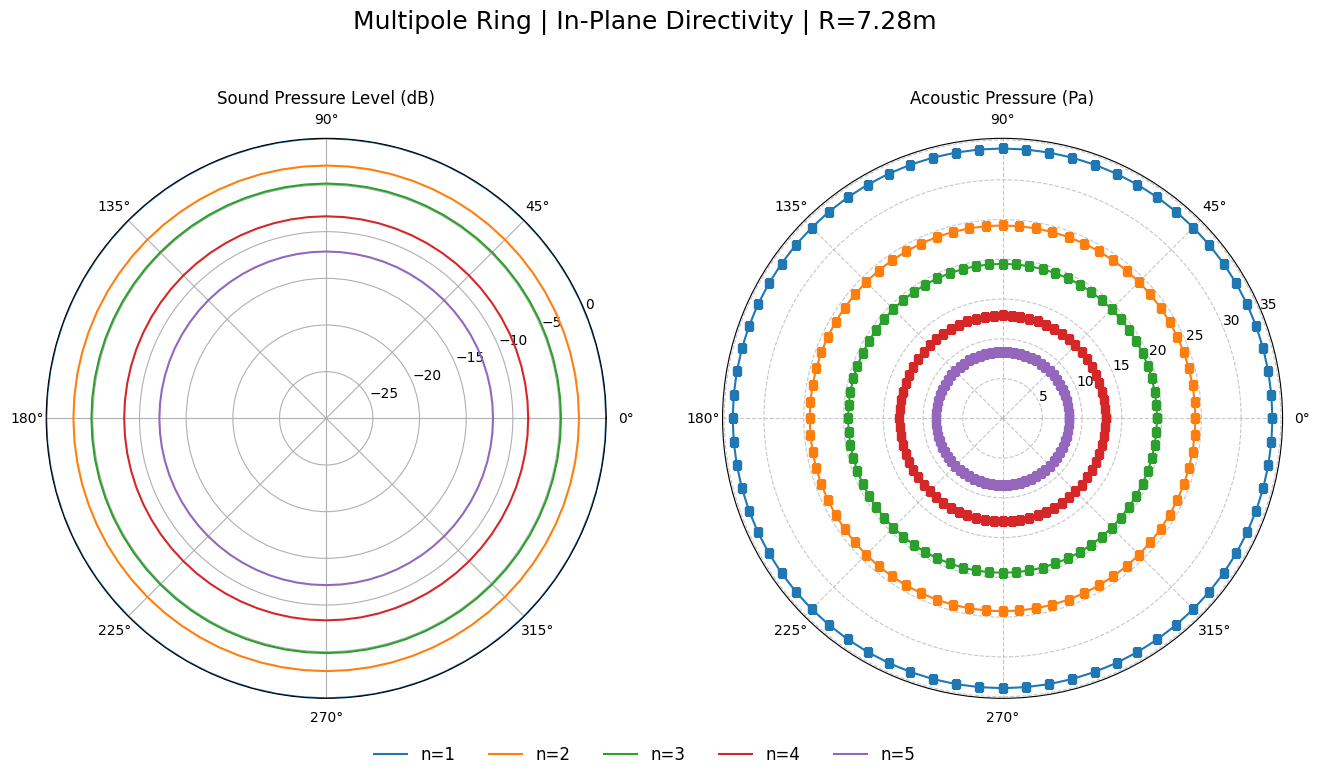

In [48]:
data_directory = "data_260828/192Sources_32Harmonics_SinglePeriod_Z_Observers"
# plot_elevation_directivity(data_dir=data_directory, 
#                            n_observers=72, 
#                            f_fundamental=107.25, 
#                            harmonics=[1, 2, 3, 4, 5], 
#                            scale='dB',
#                            legend=True,
#                            add_title="Multipole Ring In-Plane SPL Directivity at R=7.28m")

# plot_elevation_directivity(data_dir=data_directory, 
#                            n_observers=72, 
#                            f_fundamental=107.25, 
#                            harmonics=[1, 2, 3, 4, 5], 
#                            scale='linear',
#                            add_title="Multipole Ring In-Plane Pressure Directivity at R=7.28m")

plot_directivity(data_directory, n_observers=72, f_fundamental=107.25,
                 legend=True, harmonics=[1,2,3,4,5], add_title='Multipole Ring | In-Plane Directivity | R=7.28m')

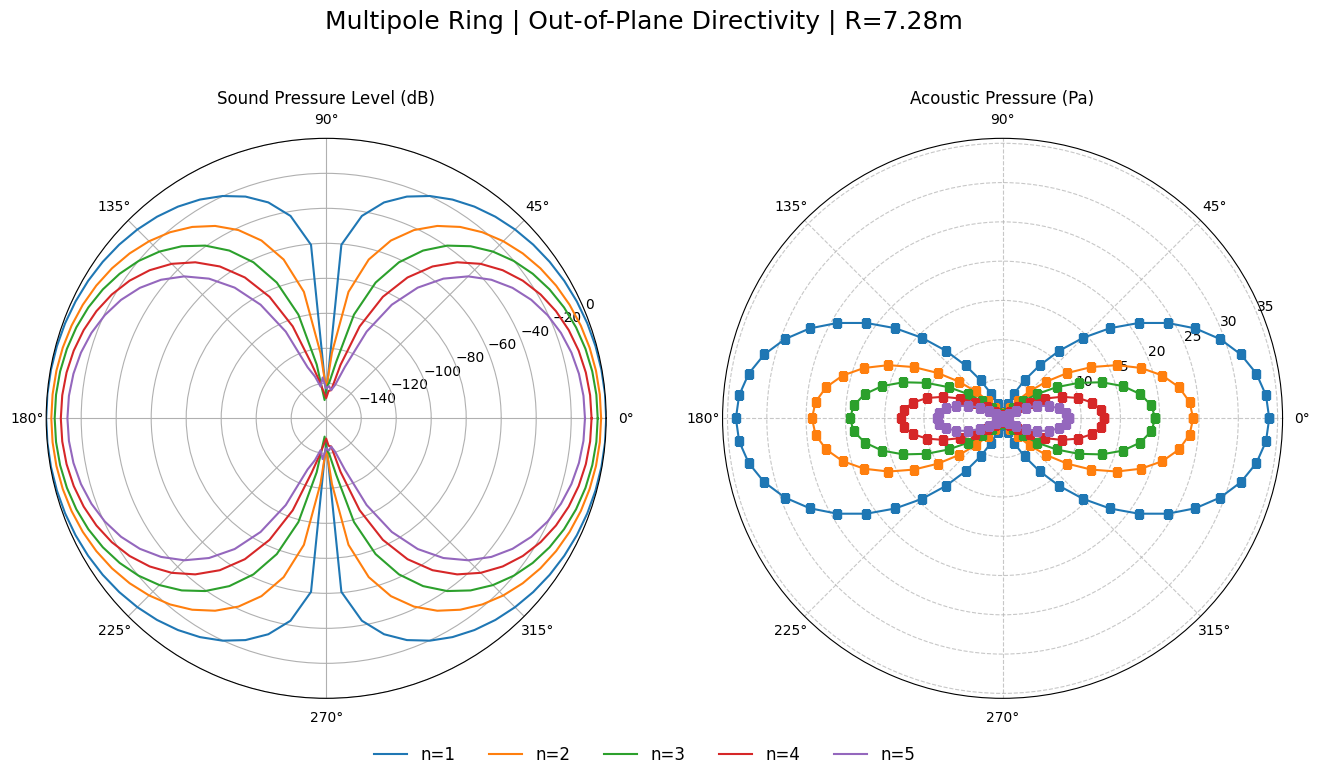

In [49]:
data_directory = Path("data_260828/192Sources_32Harmonics_SinglePeriod_Y_Observers")

# plot_elevation_directivity(data_dir=data_directory, 
#                            n_observers=72, 
#                            f_fundamental=107.25, 
#                            harmonics=[1, 2, 3, 4, 5], 
#                            scale='linear')
# plot_elevation_directivity(data_dir=data_directory, 
#                            n_observers=72, 
#                            f_fundamental=107.25, 
#                            harmonics=[1, 2, 3, 4, 5], 
#                            scale='dB')

# obs_files = sorted(data_directory.glob(f'analytical*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=np.linspace(0, t_ring.max(), 4),#47.808e-3/2,
#                                      col='P_obs',
#                                      title='Multipole Ring Spatial Pressure Lobes',
#                                      legend=True,
#                                      scale=(1/3))


plot_directivity(data_directory, n_observers=72, f_fundamental=107.25,
                 legend=True, harmonics=[1,2,3,4,5], add_title='Multipole Ring | Out-of-Plane Directivity | R=7.28m')

In [44]:
# data_directory = Path("data_260828/192Sources_32Harmonics_SinglePeriod_X_Observers")

# obs_id = '01'
# temporal_data = FWHDataset(filepath=data_directory / f'analytical_{obs_id}.dat')

# # p_ring = temporal_data.data['P_obs'] /3 
# # t_ring = temporal_data.data['Time']

# # dt = t_ring.iloc[1] - t_ring.iloc[0]
# # N = len(p_ring)
# # freqs = np.fft.rfftfreq(N, d=dt)
# # fft_amp = (2.0 / N) * np.abs(np.fft.rfft(p_ring))

# # p_ref = 2e-5
# # spl_ana = 20 * np.log10((fft_amp / np.sqrt(2)) / p_ref + 1e-12)

# # T_ref = t_ring.max()
# # f_bpf = 1.0 / T_ref
# # harmonics_ring = np.arange(1, 33)
# # ana_peaks_ring = []

# # for h in harmonics_ring:
# #     target_f = h * f_bpf
# #     idx = np.argmin(np.abs(freqs - target_f))
# #     ana_peaks_ring.append(spl_ana[idx])

# # fig, (ax1, ax2) = plt.subplots(figsize=(12,6), ncols=2)
# # ax1.plot(t_ring / time_period, p_ring, c='red', label="Multipole Ring")
# # ax1.plot(t_ana / time_period, p_ana, label='Single Point Multipole', c='blue', alpha=0.6)
# # ax1.grid(True)
# # ax1.legend()
# # ax1.set_ylabel('Acoustic Pressure (Pa)')
# # ax1.set_xlabel(f't/T, T={time_period * 1000:.3f} ms')


# # ax2.vlines(harmonics_ring, ymin=0, ymax=ana_peaks_ring, color='red')
# # ax2.plot(harmonics_ring, ana_peaks_ring, marker='s', color='none', markeredgecolor='red', label='Multipole Ring')
# # ax2.vlines(harmonics, ymin=0, ymax=ana_peaks, color='blue', alpha=0.6)
# # ax2.plot(harmonics, ana_peaks, marker='o', color='none', markeredgecolor='blue', label='Single Point Multipole')
# # ax2.set_xlabel("Harmonic Number")
# # ax2.set_ylabel(r"Sound Pressure Level (dB), Reference = 2 $\times$ 10$^5$ Pa")
# # ax2.grid(True)
# # ax2.set_ylim(bottom=0, top=120)
# # ax2.legend()
# # fig.suptitle("Thickness Noise Signal Comparison of Multipole Using a Single Point and Ring Assembly")
# # fig.tight_layout()
# # fig.subplots_adjust(top=0.92)

# plot_elevation_directivity(data_dir=data_directory, 
#                            n_observers=72, 
#                            f_fundamental=107.25, 
#                            harmonics=[1, 2, 3, 4, 5], 
#                            scale='linear',
#                            add_title='Multipole Ring Out-of-Plane Pressure Directivity at R=7.28m')
# plot_elevation_directivity(data_dir=data_directory, 
#                            n_observers=72, 
#                            f_fundamental=107.25, 
#                            harmonics=[1, 2, 3, 4, 5], 
#                            scale='dB',
#                            add_title="Multipole Ring Out-of-Plane SPL Directivity at R=7.28m")

# obs_files = sorted(data_directory.glob(f'analytical*.dat'))
# datasets = [FWHDataset(filepath=f) for f in obs_files]
# FWHPlotter.plot_directivity_snapshot(reference=datasets,
#                                      target_time=np.linspace(0, t_ring.max(), 4),#47.808e-3/2,
#                                      col='P_obs',
#                                      title='Multipole Ring Spatial Pressure Lobes',
#                                      legend=True,
#                                      scale=(1/3))